# Hands-on: Run inference on a Toy SST model

This notebook describes how to run inference of in anemoi from an existing checkpoint. It is an overly simple model, with very limited inputs, and very limited compute. It is not expected to perform well, and users should not expect skillful results, instead the intent is to play around with how the model works.

**Resources:**

[anemoi-inference](https://anemoi-inference.readthedocs.io/en/latest/apis/level1.html) package.

## Setup

In [1]:
#ensure in the right dir if not already
current_dir = %pwd
if not (current_dir.endswith("ToySSTProblem") or current_dir.endswith("app")):
    %cd ToySSTProblem
%pwd

'/etc/ecmwf/nfs/dh1_home_a/ecm4259/ToySSTProblem'

We need to ensure we are working in a suitable environment. To enable this we have provided a requirements.txt file. This requires **python 3.12** — other Python versions (e.g. 3.11) may work but are not tested and may encounter package compatibility issues. To set your environment up, first load this version of python.

To keep things portable and avoid conflicts with other packages installed on your system, the cell below creates a dedicated virtual environment (`.venv-toysst`) and installs the required libraries into it, rather than into your user/global site-packages. Set `do_install` to `True` and run the cell below.

**Note:** after installation you need to select the **ToySST (.venv-toysst)** kernel from the kernel picker (top right of the notebook) and restart before continuing.

In [2]:
# Set 'do_install' to False to skip installation (e.g. if already done in a Docker container).
# Set 'do_install' to True to create/populate the dedicated virtual environment.

import os
import shutil
import subprocess
import sys
from pathlib import Path

do_install = True  # Set to True to install/update requirements

venv_dir = Path.cwd() / ".venv-toysst"
venv_python = venv_dir / ("Scripts/python.exe" if os.name == "nt" else "bin/python")
pip_tmp_dir = Path.cwd() / ".pip_tmp"
pip_env = os.environ.copy()
pip_env["TMPDIR"] = str(pip_tmp_dir)

if do_install:
    pip_tmp_dir.mkdir(exist_ok=True)
    try:
        if not venv_dir.exists():
            print(f"Creating virtual environment at {venv_dir}")
            subprocess.check_call([sys.executable, "-m", "venv", str(venv_dir)])

        # These optional native extensions are not required; Anemoi uses its portable fallback.
        subprocess.call([
            str(venv_python), "-m", "pip", "uninstall", "-y",
            "torch-cluster", "torch-scatter", "torch-sparse",
        ], env=pip_env)

        pip = [str(venv_python), "-m", "pip", "install", "--no-cache-dir"]
        subprocess.check_call([*pip, "--upgrade", "pip"], env=pip_env)
        subprocess.check_call([*pip, "-r", "requirements.txt"], env=pip_env)
        subprocess.check_call([*pip, "ipykernel"], env=pip_env)
        subprocess.check_call([
            str(venv_python), "-m", "ipykernel", "install",
            "--user", "--name", "toysst", "--display-name", "ToySST (.venv-toysst)",
        ])
    finally:
        shutil.rmtree(pip_tmp_dir, ignore_errors=True)

    print('')
    print("*" * 97)
    print("Installation complete. Select the 'ToySST (.venv-toysst)' kernel from the kernel picker, then restart before continuing.")
    print("*" * 97)

Installed kernelspec toysst in /home/ecm4259/.local/share/hpc-gpu-singleuser-jupyter/kernels/toysst

*************************************************************************************************
Installation complete. Select the 'ToySST (.venv-toysst)' kernel from the kernel picker, then restart before continuing.
*************************************************************************************************


In [29]:
# Import the necessary modules

import os
import shutil
import subprocess
import sys
from pathlib import Path

import torch
import yaml
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

from anemoi.inference.checkpoint import Checkpoint

from tqdm import tqdm
import zarr
import s3fs

import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime, timedelta
from scipy.interpolate import griddata

%matplotlib inline


#### Obtain data
If you have already run the training_ToySST notebook, you will have already obtained the data needed. Otherwise, a tarball with output from a pre-trained model is available on S3 cloud storage. The below cell will pull this if required.

In [30]:
## First pull the output from a pre-trained model, and change permissions.
## This should create a directory "pretrained_outputs" containing checkpoints, logs and plots

if Path("../pretrained_outputs_v2.tgz").exists():
    print("pretrained data exists")
else:
    print("Downloading pretrained outputs")
    !curl -L https://object-store.os-api.cci1.ecmwf.int/ecmwf-training-nwp-ml/pretrained_outputs_v2.tgz | tar xz -C ..


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  884M  100  884M    0     0  75.7M      0  0:00:11  0:00:11 --:--:-- 84.3M


In [31]:
# Next pull the dataset in zarr format. This will create a file called ToySSTDataset.zarr
class ProgressStore:
    def __init__(self, store, pbar):
        self.store = store
        self.pbar = pbar

    def __getitem__(self, key):
        value = self.store[key]
        self.pbar.update(1)  # update per chunk
        return value

    def keys(self):
        return self.store.keys()

    def __iter__(self):
        return iter(self.store)

    def __len__(self):
        return len(self.store)

    def __contains__(self, key):
        return key in self.store


if Path("../ToySSTDataset.zarr").exists():
    print("dataset zarr file exists")
else:
    print("Downloading dataset zarr file")

    s3 = s3fs.S3FileSystem(
        anon=True,
        client_kwargs={"endpoint_url": "https://object-store.os-api.cci1.ecmwf.int"}
    )

    store = s3fs.S3Map(
        root="s3://ecmwf-training-nwp-ml/ToySSTDataset.zarr",
        s3=s3,
        check=False
    )

    local_store = zarr.DirectoryStore("../ToySSTDataset.zarr")

    total = len(store)  # number of chunks/files

    with tqdm(total=total, desc="Copying Zarr dataset") as pbar:
        wrapped_store = ProgressStore(store, pbar)
        zarr.copy_store(wrapped_store, local_store, if_exists="replace")

    print("✅ Dataset copied to ToySSTDataset.zarr")

dataset zarr file exists


## Investigate the checkpoint

Anemoi-training creates checkpoints throughout the training process. These contain the learned weights, which the model uses to make predictions, along with various metadata about the model.

We've provided a checkpoint from a trained model, based on the ToySST problem shown in the training_ToySST.ipynb notebook.

In [32]:
ckpt_file = "../pretrained_outputs/checkpoint/2ece55884e0a415d83e8a96ddfec351b/inference-last.ckpt"

#### Investigate the checkpoint

We first see that the checkpoint contains all the relevant information about the required inputs for the model:

In [33]:
print("Loading checkpoint...")
ckpt = Checkpoint(ckpt_file)
print(ckpt)

# Variables used during training (anemoi-inference >= 0.11 stores these per dataset):
meta = ckpt.multi_dataset_metadata['data']
print("Number of variables:", len(meta.variable_categories()))
print(f"Forcing variables: {meta.select_variables(include=['forcing'])}")
print(f"Diagnostic variables: {meta.select_variables(include=['diagnostic'])}")
print(f"Prognostic variables: {meta.select_variables(include=['prognostic'])}")


Old metadata format detected. Please update your weights.


Loading checkpoint...
Checkpoint(../pretrained_outputs/checkpoint/2ece55884e0a415d83e8a96ddfec351b/inference-last.ckpt)
Number of variables: 11
Forcing variables: ['2t', 'cos_julian_day', 'cos_latitude', 'cos_local_time', 'cos_longitude', 'insolation', 'sin_julian_day', 'sin_latitude', 'sin_local_time', 'sin_longitude']
Diagnostic variables: []
Prognostic variables: ['sst']


We can also probe the model architecture. Here we see the number of channels, the processor type etc. 

In [34]:
model = torch.load(ckpt.path, weights_only=False, map_location=torch.device('cpu'))
model

AnemoiModelInterface(
  (pre_processors): ModuleDict(
    (data): Processors [forward](ModuleDict(
      (normalizer): InputNormalizer()
      (const_imputer): ConstantImputer()
    ))
  )
  (post_processors): ModuleDict(
    (data): Processors [inverse](ModuleDict(
      (const_imputer): ConstantImputer()
      (normalizer): InputNormalizer()
    ))
  )
  (pre_processors_tendencies): ModuleDict()
  (post_processors_tendencies): ModuleDict()
  (model): AnemoiModelEncProcDec(
    (node_attributes): NamedNodesAttributes(
      (trainable_tensors): ModuleDict(
        (data): TrainableTensor()
        (hidden): TrainableTensor()
      )
    )
    (encoder_graph_provider): ModuleDict(
      (data): StaticGraphProvider(
        (trainable): TrainableTensor()
      )
    )
    (encoder): ModuleDict(
      (0): GraphTransformerForwardMapper(
        (proc): GraphTransformerMapperBlock(
          (lin_key): Linear(in_features=128, out_features=128, bias=True)
          (lin_query): Linear(in_f

We can also look at the total number of weights, i.e. the number of learnable parameters:

In [35]:
print(f"Number of weights: {sum(p.numel() for p in model.parameters() if p.requires_grad)}")

Number of weights: 4676257


## Producing a forecast

Running the model for inference requires a yaml configuraton file, and a set of inputs. For our Toy SST example, the inputs are initial conditions, and atmospheric forcing (2mT). We retrieve these input conditions from the same dataset that we used to train the model, this time taking dates from 2023, the validation period we defined in our training configuration (ToySST.yaml).

Here we make a single forecast, using anemoi-inference. The contents of the yaml configuration file for anemoi inference is shown here. This defines the forecast set up, such as the date to begin the forecast, the forecast length, and where to obtain the forcing data.


In [36]:
# Load our minimal configuration file
config_path = Path("./inference_ToySST.yaml")
with open(config_path, 'r') as f:
    config = yaml.safe_load(f)

print("Inference Configuration:")
print("=" * 50)
print(yaml.dump(config, default_flow_style=False))

Inference Configuration:
checkpoint: ../pretrained_outputs/checkpoint/2ece55884e0a415d83e8a96ddfec351b/inference-last.ckpt
date: 2023-01-05
input:
  dataset:
    datasets: ../ToySSTDataset.zarr
    end: 2024-12-31
    start: 2020-01-01
lead_time: 360
output:
  tee:
    outputs:
    - truth:
        output:
          netcdf:
            path: Truth.nc
    - netcdf:
        path: Predictions.nc



We see the path to the checkpoint, which we inspected earlier. We see a start date of 5th January 2023. The 'input' command notes that we are predicting for the validation period within the dataset. We also give a lead time (here 15 days - 360 hours) and information on the output. Data can be output different data formats, including grib and netcdf. Here we tell anemoi-inference to 'tee' the output, and output the truth (i.e. a copy of the targets from the original zarr dataset) to the file `Truth.nc`, and output predictions to the file `Predicitons.nc`

### Run the forecast



Inference can easily be run on the command line with
```bash
anemoi-inference run config_name.yaml
```

Here we wrap the command for the notebook

In [37]:
# Execute inference using subprocess
print("Starting ML-ocean inference...")
print("=" * 50)

process = subprocess.Popen(
    [sys.executable, "-m", "anemoi.inference", "run", "inference_ToySST.yaml"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,  # Merge stderr into stdout
    text=True,
    bufsize=1,  # Line buffered
    universal_newlines=True
)

# Stream output
for line in iter(process.stdout.readline, ''):
    if line:
        print(line.rstrip())  # Print immediately to Jupyter cell

# Wait for completion
return_code = process.wait()

print("=" * 50)
if return_code == 0:
    print("Inference completed successfully!")
else:
    print(f"Inference failed with return code {return_code}")


Starting ML-ocean inference...
2026-09-29 16:56:54 INFO Using DefaultRunner runner, device=cuda
2026-09-29 16:56:54 INFO Loading multi-dataset metadata with dataset name `data`
2026-09-29 16:56:54 INFO [data] Pre processors: []
2026-09-29 16:56:54 INFO [data] Post processors: []
2026-09-29 16:56:54 WARNING Old metadata format detected. Please update your weights.
2026-09-29 16:56:54 INFO Loading `config.prognostic_input` from `config.input`
2026-09-29 16:56:54 INFO [data] Prognostics input: DatasetInput((), {'datasets': '../ToySSTDataset.zarr', 'start': '2020-01-01', 'end': '2024-12-31'})
2026-09-29 16:56:54 INFO [data] Constant forcings input: EmptyInput(constant_forcings)
2026-09-29 16:56:54 INFO Loading `config.dynamic_forcings` from `config.input`
2026-09-29 16:56:54 INFO [data] Dynamic forcings input: DatasetInput((), {'datasets': '../ToySSTDataset.zarr', 'start': '2020-01-01', 'end': '2024-12-31'})
2026-09-29 16:56:54 INFO Loading `config.boundary_forcings` from `config.input`
20

# Inspect the generated forecast

As a reminder, the model here is very much a toy example. It was trained on a very limited amount of data, with a very small model (`num_channels`). Given these limitations, we don't expect it to give good results. This notebook merely provides a (technical) working example. Once you are comfortable with the anemoi workflow shown here, you are encouraged to expand on it, e.g. by training on larger datasets with a more appropriate selection of inputs and model architecture, or by adapting the configurations to your own problems.

### Plot a field

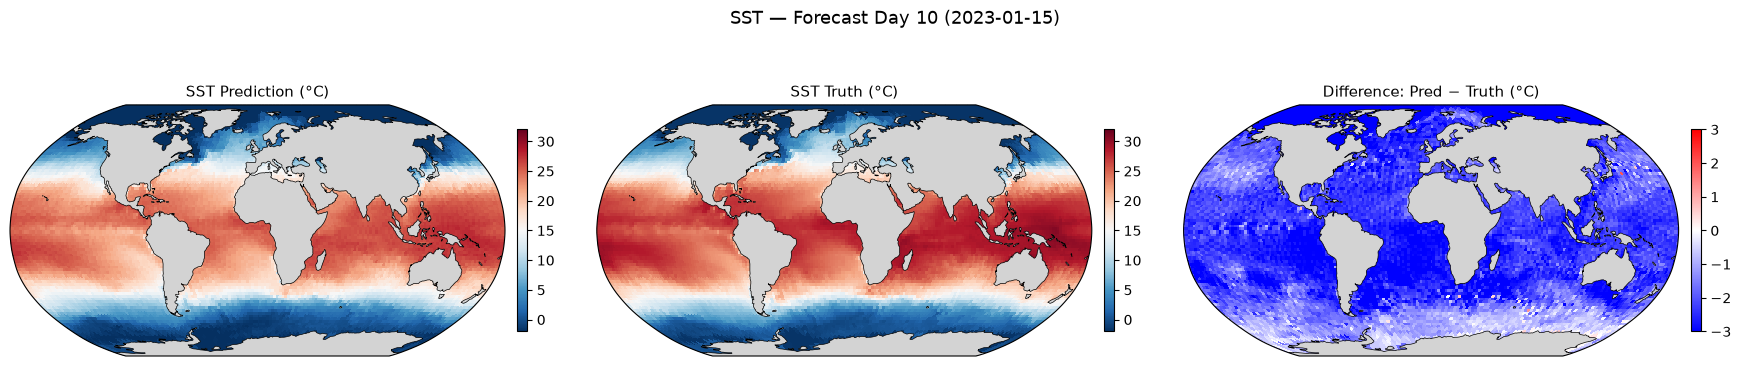

In [38]:
# Load predictions
ds_pred = nc.Dataset('./Predictions.nc')
times    = ds_pred.variables['time'][:]
lats     = ds_pred.variables['latitude'][:]
lons     = ds_pred.variables['longitude'][:]
sst_pred = ds_pred.variables['sst'][:]   # shape: (time, values), units: K
ds_pred.close()

# Load truth
ds_truth  = nc.Dataset('./Truth.nc')
sst_truth = ds_truth.variables['sst'][:]
ds_truth.close()

# Build forecast datetimes (base = 2023-01-05)
base_date      = datetime(2023, 1, 5)
forecast_dates = [base_date + timedelta(seconds=int(t)) for t in times]

# Regular grid for interpolation
lon_reg = np.linspace(0, 360, 720)
lat_reg = np.linspace(-90, 90, 360)
lon_grid, lat_grid = np.meshgrid(lon_reg, lat_reg)

def regrid(data_1d, lons, lats, lon_grid, lat_grid):
    """Interpolate unstructured ocean points onto a regular lon/lat grid."""
    valid = ~np.isnan(data_1d)
    return griddata(
        (lons[valid], lats[valid]), data_1d[valid],
        (lon_grid, lat_grid), method='nearest'
    )

# --- Spatial plot: forecast day 10 (3 panes: prediction, truth, difference) ---
day_idx   = 10
day_label = forecast_dates[day_idx].strftime('%Y-%m-%d')

pred_day  = sst_pred[day_idx]  - 273.15   # K -> °C
truth_day = sst_truth[day_idx] - 273.15
diff_day  = pred_day - truth_day

pred_grid  = regrid(pred_day,  lons, lats, lon_grid, lat_grid)
truth_grid = regrid(truth_day, lons, lats, lon_grid, lat_grid)
diff_grid  = regrid(diff_day,  lons, lats, lon_grid, lat_grid)

proj = ccrs.Robinson()
land  = cfeature.LAND
coast = cfeature.COASTLINE

fig, axes = plt.subplots(
    1, 3, figsize=(18, 4),
    subplot_kw={'projection': proj}
)

panels = [
    (pred_grid,  'RdBu_r', -2, 32, 'SST Prediction (°C)'),
    (truth_grid, 'RdBu_r', -2, 32, 'SST Truth (°C)'),
    (diff_grid,  'bwr',    -3,  3,  'Difference: Pred − Truth (°C)'),
]

for ax, (data, cmap, vmin, vmax, title) in zip(axes, panels):
    ax.set_global()
    mesh = ax.pcolormesh(
        lon_grid, lat_grid, data,
        cmap=cmap, vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree(), shading='auto'
    )
    ax.add_feature(land,  facecolor='lightgray', zorder=1)
    ax.add_feature(coast, linewidth=0.5, zorder=2)
    plt.colorbar(mesh, ax=ax, shrink=0.6, pad=0.02)
    ax.set_title(title, fontsize=11)

fig.suptitle(f'SST — Forecast Day 10 ({day_label})', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()


### Plot a forecast time-series 

Next we plot a timeseries from the dataset (i.e. the 'truth') and the model predictions. You can select different locations by chaging the latitude and longitude on the second line, and assess the model at different locations.

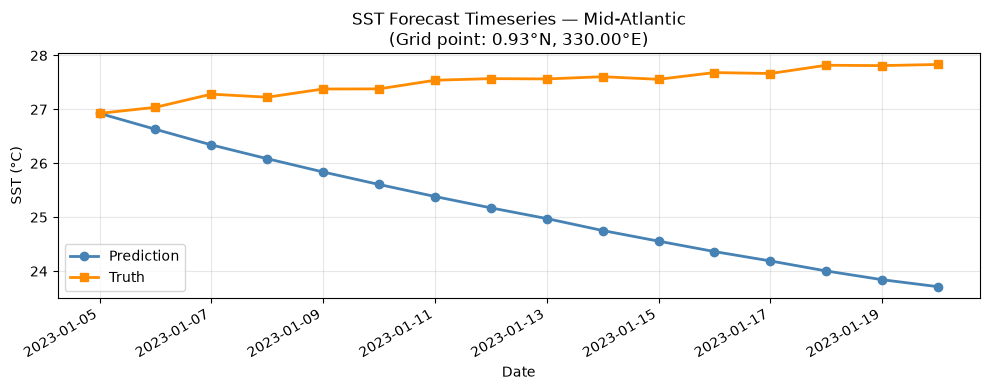

In [39]:
# --- Timeseries: mid-Atlantic point (0°N, 330°E ≈ 30°W) ---
target_lat, target_lon = 0.0, 330.0
dist        = np.sqrt((lats - target_lat)**2 + (lons - target_lon)**2)
nearest_idx = np.argmin(dist)
actual_lat  = lats[nearest_idx]
actual_lon  = lons[nearest_idx]

sst_pred_ts  = sst_pred[:, nearest_idx]  - 273.15   # °C
sst_truth_ts = sst_truth[:, nearest_idx] - 273.15

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(forecast_dates, sst_pred_ts,  marker='o', linewidth=2, color='steelblue', label='Prediction')
ax.plot(forecast_dates, sst_truth_ts, marker='s', linewidth=2, color='darkorange', label='Truth')
ax.set_xlabel('Date')
ax.set_ylabel('SST (°C)')
ax.set_title(
    f'SST Forecast Timeseries — Mid-Atlantic\n'
    f'(Grid point: {actual_lat:.2f}°N, {actual_lon:.2f}°E)',
    fontsize=12
)
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


We see that the model makes qualitatively reasonable predictions - plotting model fields shows a reasonable range of temperature, with the correct widescale patterns of colder temperature at the poles, and warmer water at the equator. However, when looking at the errors, and when plotting timeseries at a point against the model truth, we see that the model struggles to correctly capture the change over time. This is not surprising given the simplicity of the model.

## Tasks

Firstly, you can investigate simple inference changes, such as plotting for a different date, or making a longer predictions by editing the `lead_time` and `date` in inference_ToySST.yaml.

As well as the final checkpoint, the model ouputs checkpoints throughout training. You can point to these intermediate checkpoints by editing inference_ToySST.yaml (you can find a list of checkpoints at `../pretrained_outputs/checkpoint/2ece55884e0a415d83e8a96ddfec351b/`, use the ones beginning with `inference`). You can create predictions from these and plot them to see how the predictions change throughout the training process as the model develops more skill.

Then you can carry out the same procedure as shown here for the models you've trained yourself using training_toySST.ipynb. To do this, point to the ckpt (checkpoint) files created by your own runs in the inference_ToySST.yaml (note these checkpoints will be in `new_training_outputs/` rather than `../pretrained_outputs/`).

